# U-Net 残差学习：照片修图训练

先建立简单、容易修改的配对训练基线：**预测图 = 输入图 + U-Net(输入图)**。
U-Net 输出 RGB 残差，最后一层初始化为零，因此训练开始时输出等于输入。

- 输入：`Images/raw/同名图片.jpg`；目标：`Images/c/同名图片.jpg`。
- `a`～`e` 是不同修图风格，通过 `TARGET_EXPERT` 选择，单次只训练一种。
- 先按照片配对、随机选取数据，再划分 train / val / test，避免同一照片泄漏。
- 本版输入、目标都缩放到 `IMAGE_SIZE × IMAGE_SIZE`，直接学习图像残差；不包含 HDRNet、双边网格或高分辨率参数映射。

**使用：** 在项目目录打开 notebook，选择已安装 PyTorch 的 Python 内核，从上到下运行。
先改下一节的常量。建议先 `MAX_PAIRS=100`、`EPOCHS=2` 验证流程，再增加数据量。


## 1. 依赖与实验配置

需要 `torch`、`numpy`、`Pillow`、`matplotlib` 和 `ipykernel`。
缺少依赖时，在当前 notebook 内核中运行 `%pip install -r requirements-retouch.txt`，随后重启内核。
PyTorch 的 CUDA 版本应根据机器选择：[官方安装说明](https://pytorch.org/get-started/locally/)。

`MAX_PAIRS` 指**划分之前的总照片对数**，不是训练集数量；`None` 表示全部。
默认 1000 对按 80% / 10% / 10% 分成 800 / 100 / 100。
改变数据或模型配置后，从配置单元重新向下执行，避免混用旧变量。


In [16]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()  # 如果内核工作目录不同，改成包含 Images 的项目路径
DATA_ROOT = PROJECT_ROOT / "Images"
INPUT_FOLDER = "raw"
TARGET_EXPERT = "c"       # "a", "b", "c", "d", "e"

MAX_PAIRS = 100          # 总配对数；None = 使用全部；先用 100 可快速试验
TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1
SEED = 42

IMAGE_SIZE = 256          # 本版把整张图缩放为正方形，非保持比例的 resize
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 1e-4
BASE_CHANNELS = 16        # 8 更轻；32 更大
LOSS_NAME = "l1"         # "l1" 或 "mse"
HORIZONTAL_FLIP = True   # 只对训练集做成对水平翻转
NUM_WORKERS = 0          # Windows / notebook 默认用 0，避免多进程启动问题
DEVICE = "auto"          # "auto", "cpu", "cuda"
PREVIEW_COUNT = 3

OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "unet_residual"


In [17]:
import csv
import json
import math
import random
import time
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


In [18]:
if TARGET_EXPERT not in {"a", "b", "c", "d", "e"}:
    raise ValueError("TARGET_EXPERT 必须为 a～e 之一")
if IMAGE_SIZE < 8 or BATCH_SIZE < 1 or EPOCHS < 1 or BASE_CHANNELS < 1:
    raise ValueError("检查 IMAGE_SIZE >= 8 及 batch、epochs、channels > 0")
if NUM_WORKERS != 0:
    raise ValueError("本自包含 notebook 请保持 NUM_WORKERS=0")
if LOSS_NAME not in {"l1", "mse"}:
    raise ValueError("LOSS_NAME 只支持 l1 或 mse")
if DEVICE not in {"auto", "cpu", "cuda"}:
    raise ValueError("DEVICE 只支持 auto / cpu / cuda")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device(("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE)
if device.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("当前 PyTorch 无可用 CUDA；使用 DEVICE='cpu' 或安装匹配的版本")

# 每次重新运行配置后生成新目录，不覆盖之前的实验。
RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
config = {
    "input_folder": INPUT_FOLDER, "target_expert": TARGET_EXPERT,
    "max_pairs": MAX_PAIRS, "ratios": [TRAIN_RATIO, VAL_RATIO, TEST_RATIO],
    "seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "base_channels": BASE_CHANNELS,
    "loss_name": LOSS_NAME, "horizontal_flip": HORIZONTAL_FLIP,
    "alignment": "center_crop_common_size_then_square_resize",
    "device": str(device), "torch_version": str(torch.__version__),
}
print("设备:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
print("结果目录:", RUN_DIR)


设备: cuda
GPU: NVIDIA GeForce GTX 1660 Ti
结果目录: c:\Users\maoru\Desktop\Master Project\outputs\unet_residual\20261020-170412-582837


## 2. 配对、选取数据和划分

只配对同名照片（不依赖文件枚举顺序）；没有目标的输入会被统计并跳过。
重复文件名会报错。使用固定随机种子打乱，取前 `MAX_PAIRS` 对，然后划分。
训练和验证数量向下取整，剩余分配给测试集；三个集合必须都有图片。
划分写入 `splits.json`，原图不会被移动或修改。


In [19]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

def index_images(folder):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f"图片目录不存在: {folder}")
    result = {}
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            key = path.stem.casefold()
            if key in result:
                raise ValueError(f"同一目录有重复照片名: {result[key]} 和 {path}")
            result[key] = path
    return result


def discover_pairs(input_dir, target_dir):
    inputs = index_images(input_dir)
    targets = index_images(target_dir)
    keys = sorted(inputs.keys() & targets.keys())
    if not keys:
        raise ValueError("找不到同名输入和目标，请检查目录及命名")
    print(f"输入 {len(inputs)} 张，目标 {len(targets)} 张，配对成功 {len(keys)} 对；"
          f"未配对输入 {len(inputs.keys() - targets.keys())} 张，"
          f"未配对目标 {len(targets.keys() - inputs.keys())} 张")
    return [{"id": key, "input": inputs[key], "target": targets[key]} for key in keys]


def split_pairs(pairs, max_pairs, ratios, seed):
    if len(ratios) != 3 or any(not math.isfinite(r) or r <= 0 for r in ratios):
        raise ValueError("三个划分比例必须为有限正数")
    if not math.isclose(sum(ratios), 1.0, abs_tol=1e-8):
        raise ValueError("TRAIN_RATIO + VAL_RATIO + TEST_RATIO 必须等于 1")
    if max_pairs is not None and (type(max_pairs) is not int or max_pairs < 1):
        raise ValueError("MAX_PAIRS 必须为正整数或 None")
    selected = list(pairs)
    random.Random(seed).shuffle(selected)
    if max_pairs is not None:
        if max_pairs > len(selected):
            print(f"MAX_PAIRS 超过可用数量，将使用全部 {len(selected)} 对")
        selected = selected[:max_pairs]
    n_train = int(len(selected) * ratios[0])
    n_val = int(len(selected) * ratios[1])
    n_test = len(selected) - n_train - n_val
    if min(n_train, n_val, n_test) < 1:
        raise ValueError("数据量太少或比例太小，导致某个集合为空；请增加 MAX_PAIRS 或调整比例")
    return {
        "train": selected[:n_train],
        "val": selected[n_train:n_train+n_val],
        "test": selected[n_train+n_val:],
    }


In [20]:
all_pairs = discover_pairs(DATA_ROOT / INPUT_FOLDER, DATA_ROOT / TARGET_EXPERT)
splits = split_pairs(all_pairs, MAX_PAIRS, (TRAIN_RATIO, VAL_RATIO, TEST_RATIO), SEED)
print({name: len(items) for name, items in splits.items()})

RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
manifest = {
    "seed": SEED,
    "splits": {
        name: [{"id": p["id"],
                "input": str(p["input"].relative_to(PROJECT_ROOT)),
                "target": str(p["target"].relative_to(PROJECT_ROOT))} for p in items]
        for name, items in splits.items()
    },
}
(RUN_DIR / "splits.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")


输入 5000 张，目标 5000 张，配对成功 5000 对；未配对输入 0 张，未配对目标 0 张
{'train': 80, 'val': 10, 'test': 10}


16208

## 3. 加载与预览

本地抽样发现 raw 与目标的尺寸略有不同。本版假设主体位置一致、差异主要来自边缘：
先按 EXIF 校正方向，再把两图都居中裁到共同宽高，最后缩放为正方形。
**这不是精确配准。先检查预览与叠加图；如果存在明显错位，需另外配准，否则像素损失可能学出模糊。**

当前 JPG 样本没有嵌入 ICC 配置，本基线将解码后的 RGB 归一化到 `[0,1]`；不涉及原始传感器 RAW 显影。
训练只做同步水平翻转，不做亮度/颜色增强，以免改变修图监督关系。


In [21]:
def read_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def center_crop(image, width, height):
    left = (image.width - width) // 2
    top = (image.height - height) // 2
    return image.crop((left, top, left + width, top + height))


def prepare_image_pair(input_path, target_path, size):
    source = read_rgb(input_path)
    target = read_rgb(target_path)
    width = min(source.width, target.width)
    height = min(source.height, target.height)
    source = center_crop(source, width, height)
    target = center_crop(target, width, height)
    return tuple(image.resize((size, size), Image.Resampling.BILINEAR)
                 for image in (source, target))


def image_to_tensor(image):
    array = np.array(image, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1).contiguous()


class PairedRetouchDataset(Dataset):
    def __init__(self, pairs, image_size, augment=False):
        self.pairs = list(pairs)
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        pair = self.pairs[index]
        try:
            source, target = prepare_image_pair(pair["input"], pair["target"], self.image_size)
        except Exception as exc:
            raise RuntimeError(f"读取配对图片失败: {pair['input']} / {pair['target']}") from exc
        if self.augment and random.random() < 0.5:
            source = ImageOps.mirror(source)
            target = ImageOps.mirror(target)
        return {"input": image_to_tensor(source), "target": image_to_tensor(target), "id": pair["id"]}


def display_image(tensor):
    return tensor.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()


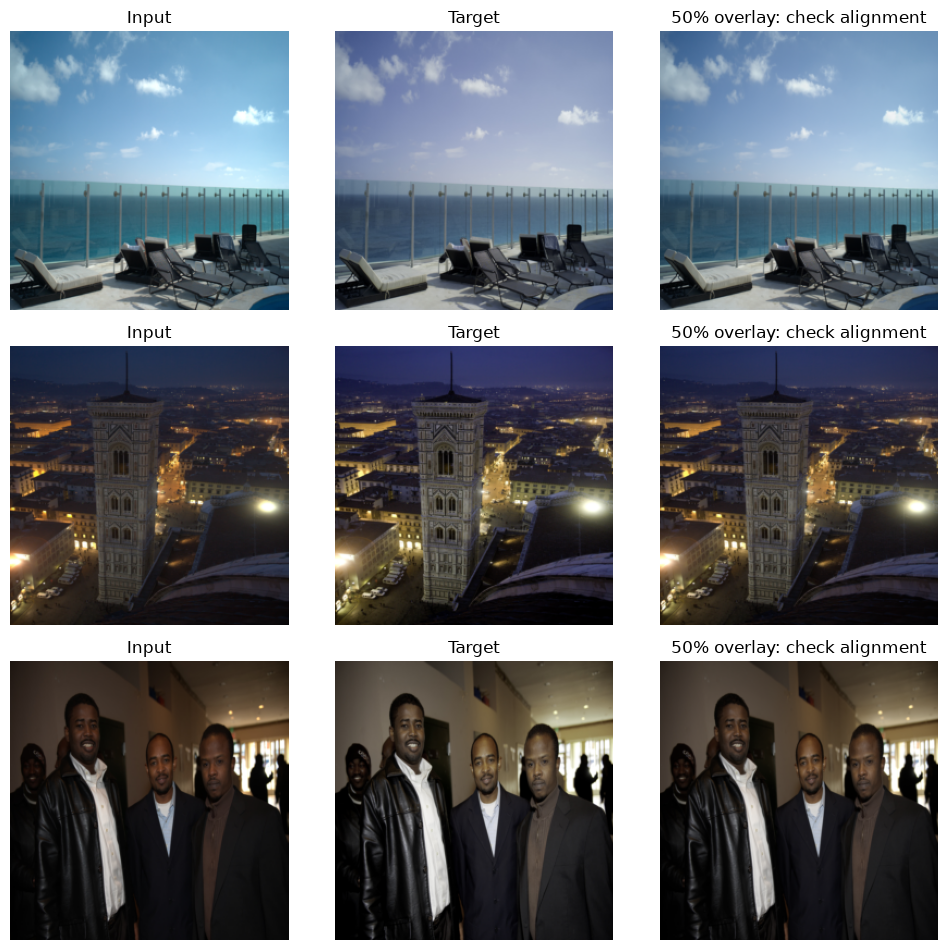

In [22]:
train_dataset = PairedRetouchDataset(splits["train"], IMAGE_SIZE, augment=HORIZONTAL_FLIP)
val_dataset = PairedRetouchDataset(splits["val"], IMAGE_SIZE)
test_dataset = PairedRetouchDataset(splits["test"], IMAGE_SIZE)
generator = torch.Generator().manual_seed(SEED)
loader_kwargs = {"batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
                 "pin_memory": device.type == "cuda"}
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

# 看训练集的无增强版本，不提前查看测试集。
preview_dataset = PairedRetouchDataset(splits["train"], IMAGE_SIZE)
n = min(PREVIEW_COUNT, len(preview_dataset))
fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n), squeeze=False)
for row in range(n):
    sample = preview_dataset[row]
    images = [sample["input"], sample["target"], 0.5*(sample["input"]+sample["target"])]
    for ax, image, title in zip(axes[row], images, ["Input", "Target", "50% overlay: check alignment"]):
        ax.imshow(display_image(image))
        ax.set_title(title)
        ax.axis("off")
fig.tight_layout()
plt.show()


## 4. 轻量 U-Net + 全局残差

三次下采样，编码器与解码器之间有同尺度跳跃连接。
每个卷积块是两层 `3×3 Conv + ReLU`，不使用 BatchNorm。
上采样使用双线性插值，再与编码器特征拼接。

最后 `1×1 Conv` 输出 3 通道残差，初始为零。训练时输出**不做 clamp 或 sigmoid**，
避免截断梯度；计算展示用 PSNR 和保存图片时才裁到 `[0,1]`。


In [23]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class ResidualUNet(nn.Module):
    def __init__(self, base_channels=16):
        super().__init__()
        b = base_channels
        self.encoder1 = DoubleConv(3, b)
        self.encoder2 = DoubleConv(b, 2*b)
        self.encoder3 = DoubleConv(2*b, 4*b)
        self.bottleneck = DoubleConv(4*b, 8*b)
        self.pool = nn.MaxPool2d(2)
        self.decoder3 = DoubleConv(8*b + 4*b, 4*b)
        self.decoder2 = DoubleConv(4*b + 2*b, 2*b)
        self.decoder1 = DoubleConv(2*b + b, b)
        self.head = nn.Conv2d(b, 3, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        z = self.bottleneck(self.pool(e3))
        z = self.decoder3(torch.cat([F.interpolate(z, size=e3.shape[-2:], mode="bilinear", align_corners=False), e3], dim=1))
        z = self.decoder2(torch.cat([F.interpolate(z, size=e2.shape[-2:], mode="bilinear", align_corners=False), e2], dim=1))
        z = self.decoder1(torch.cat([F.interpolate(z, size=e1.shape[-2:], mode="bilinear", align_corners=False), e1], dim=1))
        return x + self.head(z)


In [24]:
model = ResidualUNet(BASE_CHANNELS).to(device)
criterion = nn.L1Loss() if LOSS_NAME == "l1" else nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(f"模型参数量: {sum(p.numel() for p in model.parameters()):,}")
print(f"训练 batch 数: {len(train_loader)}，验证 batch 数: {len(val_loader)}")


模型参数量: 487,331
训练 batch 数: 10，验证 batch 数: 2


## 5. 训练与验证

每轮计算 train / val 损失与 RGB PSNR；验证集选择最佳模型，测试集不参与选模型。
同时统计直接使用输入图的 PSNR，判断模型是否优于“不修图”。
PSNR 是逐图计算后取平均，峰值为 1；它不是 HDRNet 原文表 3 的 Lab 指标。
每个 epoch 更新 `history.csv`，保存验证损失最低的 `best.pt`。
若要开始全新实验，请从配置单元重新运行。


In [25]:
def image_psnr(prediction, target):
    mse = (prediction.clamp(0, 1) - target).square().flatten(1).mean(1)
    return -10.0 * torch.log10(mse.clamp_min(1e-10))


def run_epoch(model, loader, criterion, device, optimizer=None, description="Eval"):
    training = optimizer is not None
    model.train(training)
    totals = {"loss": 0.0, "psnr": 0.0, "input_psnr": 0.0}
    count = 0
    with torch.set_grad_enabled(training):
        for batch_index, batch in enumerate(loader, start=1):
            source = batch["input"].to(device, non_blocking=True)
            target = batch["target"].to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            prediction = model(source)
            loss = criterion(prediction, target)
            if not torch.isfinite(loss):
                raise FloatingPointError("损失出现 NaN / Inf，请检查数据及学习率")
            if training:
                loss.backward()
                optimizer.step()
            n = source.shape[0]
            totals["loss"] += loss.item() * n
            totals["psnr"] += image_psnr(prediction.detach(), target).sum().item()
            totals["input_psnr"] += image_psnr(source, target).sum().item()
            count += n
            if training and (batch_index == 1 or batch_index % 25 == 0):
                print(f"{description} batch {batch_index}/{len(loader)} | loss {totals['loss']/count:.5f}")
    if count == 0:
        raise ValueError("DataLoader 为空")
    return {key: value/count for key, value in totals.items()}


In [26]:
history = []
best_val_loss = float("inf")
for epoch in range(1, EPOCHS + 1):
    started = time.perf_counter()
    train_metrics = run_epoch(model, train_loader, criterion, device, optimizer, f"Train {epoch}/{EPOCHS}")
    val_metrics = run_epoch(model, val_loader, criterion, device, description=f"Val {epoch}/{EPOCHS}")
    row = {"epoch": epoch, "seconds": time.perf_counter() - started,
           **{f"train_{k}": v for k, v in train_metrics.items()},
           **{f"val_{k}": v for k, v in val_metrics.items()}}
    history.append(row)
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        torch.save({"model_state_dict": model.state_dict(), "config": config,
                    "epoch": epoch, "val_loss": best_val_loss}, RUN_DIR / "best.pt")
    with (RUN_DIR / "history.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    print(f"Epoch {epoch:02d} | train loss {row['train_loss']:.5f} | "
          f"val loss {row['val_loss']:.5f} | val PSNR {row['val_psnr']:.2f} dB | "
          f"input PSNR {row['val_input_psnr']:.2f} dB | {row['seconds']:.1f}s")
print("最佳验证损失:", best_val_loss)
print("模型保存到:", RUN_DIR / "best.pt")


Train 1/20 batch 1/10 | loss 0.05387
Epoch 01 | train loss 0.06960 | val loss 0.06971 | val PSNR 22.62 dB | input PSNR 22.63 dB | 22.8s
Train 2/20 batch 1/10 | loss 0.05261
Epoch 02 | train loss 0.06944 | val loss 0.06973 | val PSNR 22.62 dB | input PSNR 22.63 dB | 20.4s
Train 3/20 batch 1/10 | loss 0.08051
Epoch 03 | train loss 0.06922 | val loss 0.06975 | val PSNR 22.61 dB | input PSNR 22.63 dB | 19.9s
Train 4/20 batch 1/10 | loss 0.08836
Epoch 04 | train loss 0.06901 | val loss 0.06977 | val PSNR 22.60 dB | input PSNR 22.63 dB | 20.2s
Train 5/20 batch 1/10 | loss 0.05414
Epoch 05 | train loss 0.06878 | val loss 0.06984 | val PSNR 22.58 dB | input PSNR 22.63 dB | 20.5s
Train 6/20 batch 1/10 | loss 0.05322
Epoch 06 | train loss 0.06858 | val loss 0.06991 | val PSNR 22.56 dB | input PSNR 22.63 dB | 21.8s
Train 7/20 batch 1/10 | loss 0.06159
Epoch 07 | train loss 0.06830 | val loss 0.07011 | val PSNR 22.52 dB | input PSNR 22.63 dB | 20.4s
Train 8/20 batch 1/10 | loss 0.08664
Epoch 08 | 

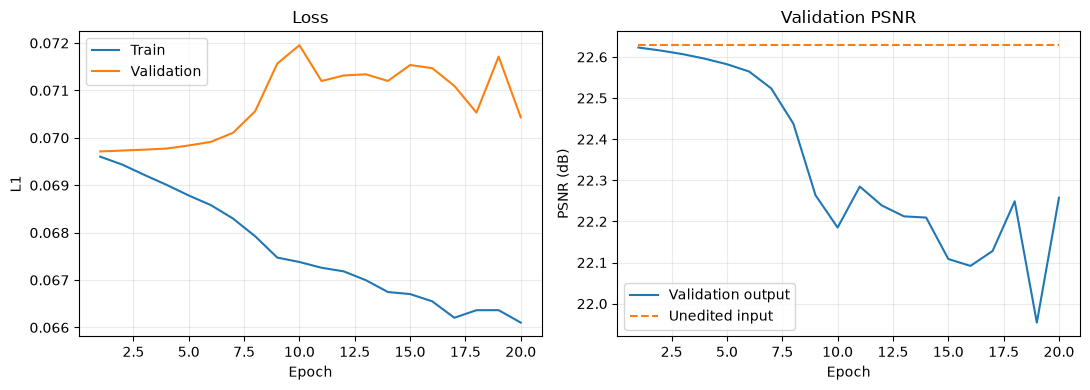

In [27]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, [r["train_loss"] for r in history], label="Train")
axes[0].plot(epochs, [r["val_loss"] for r in history], label="Validation")
axes[0].set(xlabel="Epoch", ylabel=LOSS_NAME.upper(), title="Loss")
axes[1].plot(epochs, [r["val_psnr"] for r in history], label="Validation output")
axes[1].plot(epochs, [r["val_input_psnr"] for r in history], "--", label="Unedited input")
axes[1].set(xlabel="Epoch", ylabel="PSNR (dB)", title="Validation PSNR")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()


## 6. 最佳模型的独立测试与可视化

训练结束、实验配置确定后运行。重新加载验证集选出的模型，再评估整个测试集。
不要根据测试结果反复挑选超参数；继续调参请看验证集。


In [28]:
checkpoint = torch.load(RUN_DIR / "best.pt", map_location=device, weights_only=True)
test_model = ResidualUNet(checkpoint["config"]["base_channels"]).to(device)
test_model.load_state_dict(checkpoint["model_state_dict"])
test_metrics = run_epoch(test_model, test_loader, criterion, device, description="Test")
test_metrics["psnr_gain"] = test_metrics["psnr"] - test_metrics["input_psnr"]
test_metrics["best_epoch"] = checkpoint["epoch"]
test_metrics["num_test_pairs"] = len(test_dataset)
(RUN_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")
print(json.dumps(test_metrics, indent=2))


{
  "loss": 0.09275494515895844,
  "psnr": 20.090614318847656,
  "input_psnr": 20.086642456054687,
  "psnr_gain": 0.0039718627929694605,
  "best_epoch": 1,
  "num_test_pairs": 10
}


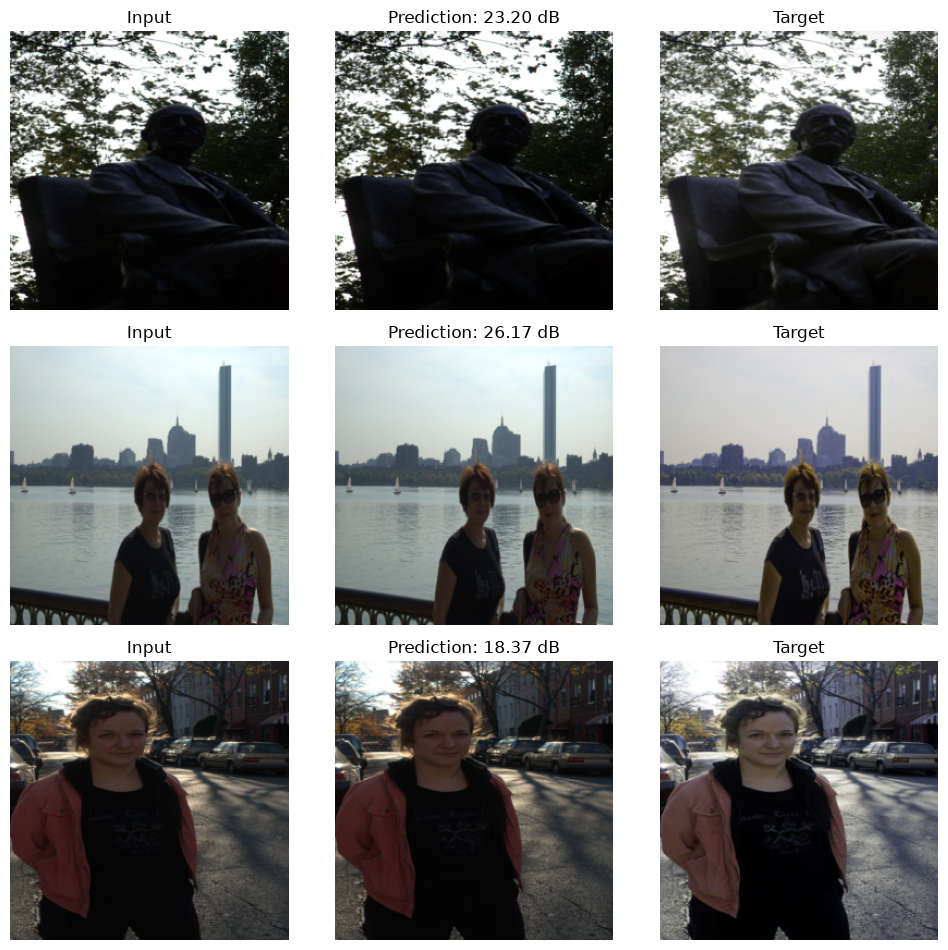

In [29]:
test_model.eval()
n = min(PREVIEW_COUNT, len(test_dataset))
fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n), squeeze=False)
preview_dir = RUN_DIR / "test_predictions"
preview_dir.mkdir(exist_ok=True)
with torch.inference_mode():
    for row in range(n):
        sample = test_dataset[row]
        prediction = test_model(sample["input"].unsqueeze(0).to(device))[0].cpu().clamp(0, 1)
        psnr = image_psnr(prediction.unsqueeze(0), sample["target"].unsqueeze(0)).item()
        images = [sample["input"], prediction, sample["target"]]
        titles = ["Input", f"Prediction: {psnr:.2f} dB", "Target"]
        for ax, image, title in zip(axes[row], images, titles):
            ax.imshow(display_image(image))
            ax.set_title(title)
            ax.axis("off")
        Image.fromarray((display_image(prediction)*255).round().astype(np.uint8)).save(preview_dir / f"{sample['id']}.png")
fig.tight_layout()
fig.savefig(RUN_DIR / "test_comparison.png", dpi=150)
plt.show()


## 7. 可选：对单张新图推理

从 checkpoint 恢复模型和图像尺寸。为保持与训练一致，输出仍是训练尺寸，
不是原图分辨率；大图直接前向不属于本基线已验证的训练设置。


In [30]:
def retouch_image(image_path, checkpoint_path, output_path, device="cpu"):
    device = torch.device(device)
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    settings = checkpoint["config"]
    model = ResidualUNet(settings["base_channels"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    size = settings["image_size"]
    image = read_rgb(image_path).resize((size, size), Image.Resampling.BILINEAR)
    with torch.inference_mode():
        prediction = model(image_to_tensor(image).unsqueeze(0).to(device))[0]
    result = Image.fromarray((display_image(prediction)*255).round().astype(np.uint8))
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    result.save(output_path)
    return result

# 取消注释后运行：
# retouch_image(DATA_ROOT / "raw" / "a0001-jmac_DSC1459.jpg",
#               RUN_DIR / "best.pt", RUN_DIR / "new_image.png", device=device)


## 建议的实验顺序

1. `MAX_PAIRS=100, EPOCHS=2`：检查数据配对、对齐和训练流程。
2. 固定划分种子，增加 `MAX_PAIRS` 和 `EPOCHS`，观察验证损失与输入 PSNR 基线。
3. 分别修改 `BASE_CHANNELS`、`IMAGE_SIZE` 或 `LOSS_NAME`，每次只改一个因素。
4. 收敛后再考虑感知损失、保边约束、原尺寸推理等扩展。

注意：数据量改变后划分也会改变；比较网络结构时应固定 `MAX_PAIRS`、种子和数据版本，
并保留每次实验的 `splits.json`。随机种子不能保证不同硬件与库版本逐位一致。
当前 checkpoint 用于推理，不保存优化器状态，不提供断点续训。

参考：[PyTorch 模型保存与加载](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)。
